# E — Validasi, bias, dan keterbatasan
**Penanggung jawab: Faaid Sakhaa (anggota E).**

Apakah distribusi perangkat mengikuti jumlah penduduk, apakah validasi malam konsisten antarperiode, dan bagian data apa yang kurang terwakili?

Analisis deskriptif ini memakai data JogjaPulse versi 1.0, bukan keluaran notebook A–D. Hasil akhir: lima grafik PNG, tabel olahan, dan ringkasan untuk presentasi. Korelasi menunjukkan keterkaitan antarwilayah, bukan bukti bahwa sampel mewakili setiap penduduk.

Sumber: [JogjaPulse, Zenodo](https://doi.org/10.5281/zenodo.23157460), terutama README dataset bagian 4–6 dan 8. Tahun serta sumber BPS untuk `pop_actual` masih berupa placeholder di README sumber; perlu dikonfirmasi sebelum laporan final.


## 1. Persiapan dan rancangan analisis
Dari folder proyek di Windows: `.venv\py313\Scripts\python -m jupyterlab notebooks/E_validasi_bias.ipynb`.
Jika data belum ada, jalankan `python scripts/download_data.py` terlebih dahulu.

- Hitung Pearson pada skala asli dan log10, serta Spearman (peringkat).
- Tampilkan semua 78 kapanewon sebagai analisis utama. Pengeluaran Gondomanan hanya uji sensitivitas yang mengikuti contoh README sumber, bukan penghapusan data salah.
- Bandingkan dua periode bawaan validasi; keduanya bertumpang tindih, sehingga bukan dua sampel independen.
- Periksa ulang rerata malam dan cakupan slot dari CSV per jam. Rerata hanya atas baris terbit; slot hilang tidak diisi nol.
- Statistik supresi memakai penyebut resmi dari file ringkasan; bukan seluruh kombinasi ruang dan waktu yang mungkin.


In [1]:
from pathlib import Path
import sys
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from IPython.display import display, Markdown
from ritme import io, style

style.apply()
%matplotlib inline
KEY = io.KAPANEWON_KEY
PERIODS = {'Dec 2021 - Jan 2022': ('2021-12-01', '2022-01-31'),
           'Dec 2021 - Apr 2022': ('2021-12-01', '2022-04-30')}
SHORT, FULL = PERIODS
io.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print('Python:', platform.python_version())
versions = {name: metadata.version(name) for name in ['pandas','numpy','matplotlib','scipy','nbformat','ipykernel']}
display(pd.Series(versions, name='versi'))

def save_plot(fig, name):
    style.add_source(fig)
    style.save(fig, name)
    plt.show()
    plt.close(fig)

def correlations(df, x, y):
    a = df[[x,y]].dropna()
    assert len(a) >= 3 and (a > 0).all().all()
    return {'n': len(a), 'Pearson': pearsonr(a[x],a[y]).statistic,
            'Pearson_log10': pearsonr(np.log10(a[x]),np.log10(a[y])).statistic,
            'Spearman': spearmanr(a[x],a[y]).statistic}


Python: 3.13.14


pandas         2.3.3
numpy          2.2.6
matplotlib    3.10.7
scipy         1.16.3
nbformat      5.11.1
ipykernel      7.4.0
Name: versi, dtype: object

## 2. Muat data dan periksa integritas
Kunci gabungan kabupaten/kota dan kapanewon membedakan dua wilayah bernama Jetis. Pemeriksaan berikut menghentikan analisis jika ada duplikat, nilai tidak valid, atau ketidakcocokan data.


In [2]:
home = io.load_home_vs_population()
night = io.load_validation_night()
tier = io.load_tier1_summary()
od = io.load_od_summary()
assert len(home) == 78 and not home.duplicated(KEY).any()
assert len(night) == 156 and not night.duplicated(['period']+KEY).any()
assert set(night['period']) == set(PERIODS)
assert home[KEY+['n_users','pop_actual','ratio']].notna().all().all()
assert night[['night_presence','slots_published_pct','n_users','pop_actual']].notna().all().all()
assert (home[['n_users','pop_actual']] > 0).all().all()
assert (night[['night_presence','n_users','pop_actual']] > 0).all().all()
assert night.slots_published_pct.between(0,100).all()
np.testing.assert_allclose(home.ratio, home.n_users/home.pop_actual)
for period, sub in night.groupby('period'):
    joined = home.merge(sub, on=KEY, validate='one_to_one', suffixes=('_h','_n'), how='outer', indicator=True)
    assert joined['_merge'].eq('both').all()
    for col in ['n_users','pop_actual']:
        np.testing.assert_allclose(joined[col+'_h'], joined[col+'_n'])
home['perangkat_per_100_penduduk'] = 100*home.n_users/home.pop_actual
home['wilayah'] = home.kapanewon+' / '+home.kab_kota
display(pd.DataFrame({'file':['home','night','tier1','od'], 'baris':[len(home),len(night),len(tier),len(od)]}))


,file,baris
0,home,78
1,night,156
2,tier1,2
3,od,1


## 3. Perangkat dengan estimasi rumah vs penduduk
Skala log memperlihatkan wilayah kecil dan besar bersama-sama. Garis 1:1 hanya referensi kesamaan angka, bukan target kualitas. Rasio perangkat per 100 penduduk bukan persentase warga yang teramati.


Grafik rasio memakai rentang sumbu berbeda pada panel terendah dan tertinggi; bandingkan angka pada sumbu, bukan panjang batang antar-panel.


,n,Pearson,Pearson_log10,Spearman
Semua wilayah,78,0.723,0.600,0.614
Tanpa Gondomanan,77,0.820,0.688,0.672


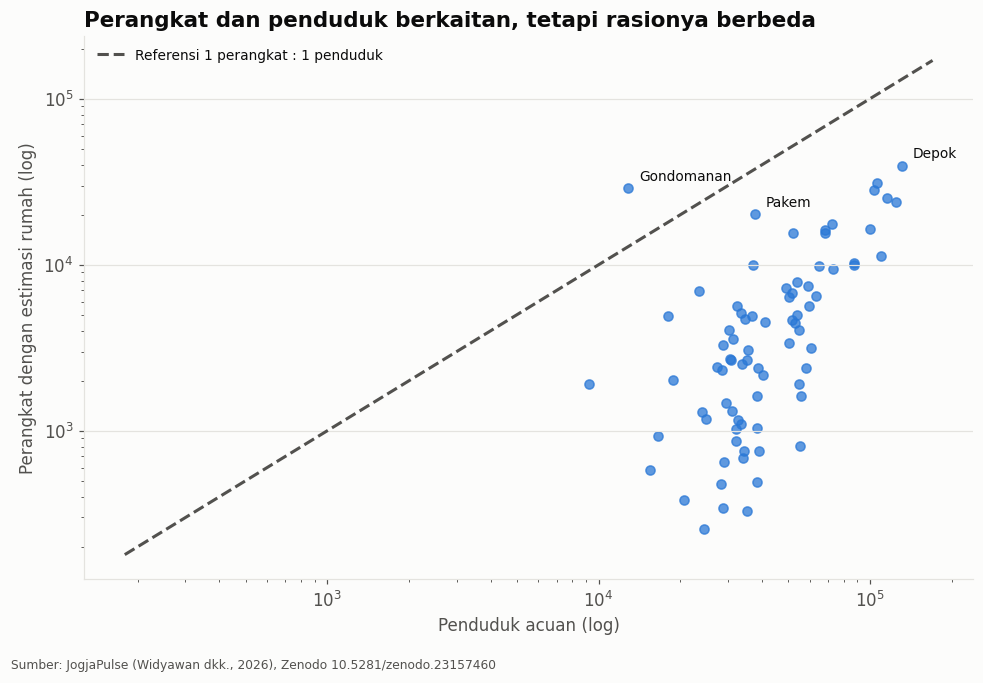

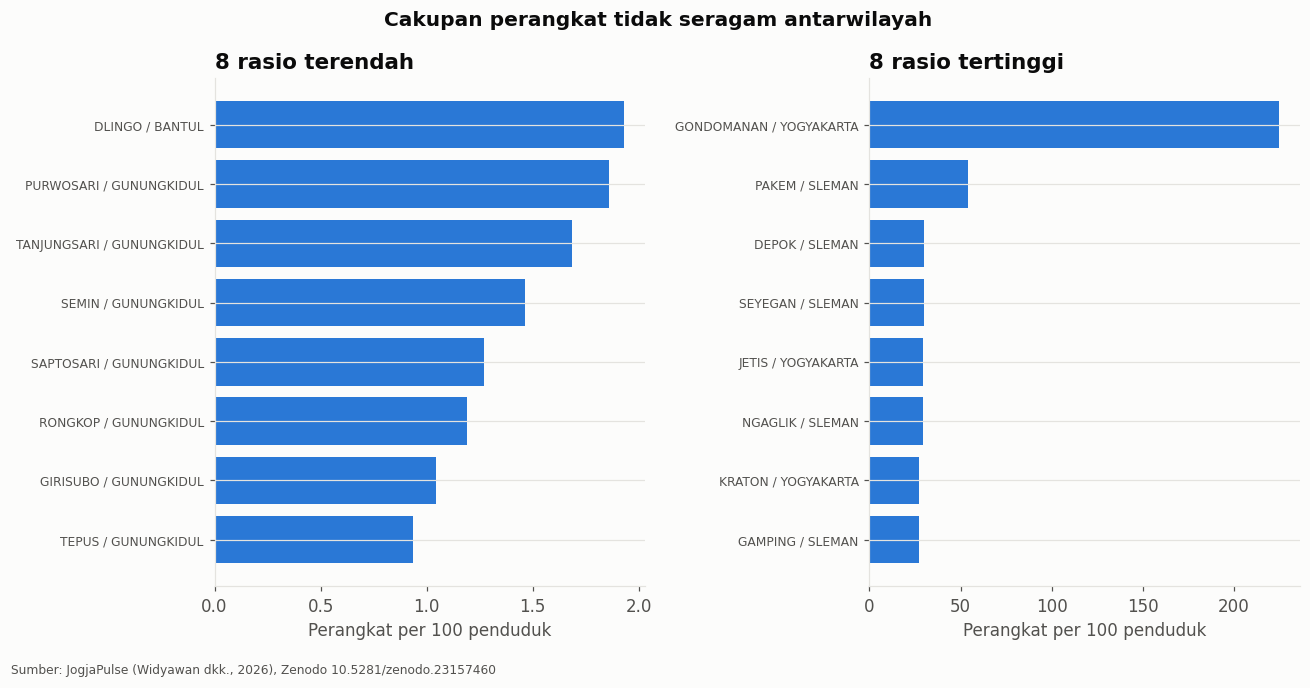

,min,median,max
kab_kota,,,
BANTUL,1.93,10.27,22.03
GUNUNGKIDUL,0.94,2.22,11.34
KULON PROGO,2.71,7.45,14.83
SLEMAN,7.49,16.33,53.86
YOGYAKARTA,3.26,14.49,224.70


In [3]:
without_g = ~((home.kab_kota == 'YOGYAKARTA') & (home.kapanewon == 'GONDOMANAN'))
home_corr = pd.DataFrame([correlations(home,'pop_actual','n_users'), correlations(home[without_g],'pop_actual','n_users')], index=['Semua wilayah','Tanpa Gondomanan'])
display(home_corr.round(3))
fig, ax = plt.subplots(figsize=(9,6))
ax.scatter(home.pop_actual, home.n_users, color=style.CATEGORICAL[0], alpha=.75)
lo, hi = min(home.pop_actual.min(),home.n_users.min())*.7, max(home.pop_actual.max(),home.n_users.max())*1.3
ax.plot([lo,hi],[lo,hi], '--', color=style.TEXT_SECONDARY, label='Referensi 1 perangkat : 1 penduduk')
for row in home.nlargest(3,'ratio').itertuples():
    ax.annotate(row.kapanewon.title(), (row.pop_actual,row.n_users), xytext=(7,5), textcoords='offset points', fontsize=9)
ax.set(xscale='log',yscale='log',xlabel='Penduduk acuan (log)',ylabel='Perangkat dengan estimasi rumah (log)',title='Perangkat dan penduduk berkaitan, tetapi rasionya berbeda')
ax.legend(fontsize=9)
fig.tight_layout()
save_plot(fig,'E_01_perangkat_vs_penduduk')

fig, axes = plt.subplots(1,2,figsize=(12,6))
for ax, frame, title in [(axes[0],home.nsmallest(8,'ratio'),'8 rasio terendah'),(axes[1],home.nlargest(8,'ratio'),'8 rasio tertinggi')]:
    frame=frame.sort_values('ratio')
    ax.barh(frame.wilayah, frame.perangkat_per_100_penduduk,color=style.CATEGORICAL[0])
    ax.set(title=title,xlabel='Perangkat per 100 penduduk')
    ax.tick_params(axis='y',labelsize=8)
fig.suptitle('Cakupan perangkat tidak seragam antarwilayah',fontweight='bold')
fig.tight_layout()
save_plot(fig,'E_02_rasio_perangkat')
display(home.groupby('kab_kota').perangkat_per_100_penduduk.agg(['min','median','max']).round(2))


## 4. Validasi malam dan sensitivitas periode
`night_presence` adalah rerata perangkat per jam pada 00.00–05.59 WIB **hanya untuk slot yang terbit**. Bandingkan hubungan dengan penduduk dan perangkat rumah. Rerata dua periode bisa berbeda akibat perubahan sampel serta supresi, bukan semata perubahan mobilitas.


,period,cakupan,pembanding,n,Pearson,Pearson_log10,Spearman
0,Dec 2021 - Apr 2022,Semua wilayah,pop_actual,78,0.707,0.596,0.601
1,Dec 2021 - Apr 2022,Semua wilayah,n_users,78,0.988,0.977,0.986
2,Dec 2021 - Apr 2022,Tanpa Gondomanan,pop_actual,77,0.825,0.702,0.661
3,Dec 2021 - Apr 2022,Tanpa Gondomanan,n_users,77,0.988,0.977,0.986
4,Dec 2021 - Jan 2022,Semua wilayah,pop_actual,78,0.797,0.652,0.634
5,Dec 2021 - Jan 2022,Semua wilayah,n_users,78,0.963,0.973,0.983
6,Dec 2021 - Jan 2022,Tanpa Gondomanan,pop_actual,77,0.824,0.718,0.679
7,Dec 2021 - Jan 2022,Tanpa Gondomanan,n_users,77,0.987,0.975,0.983


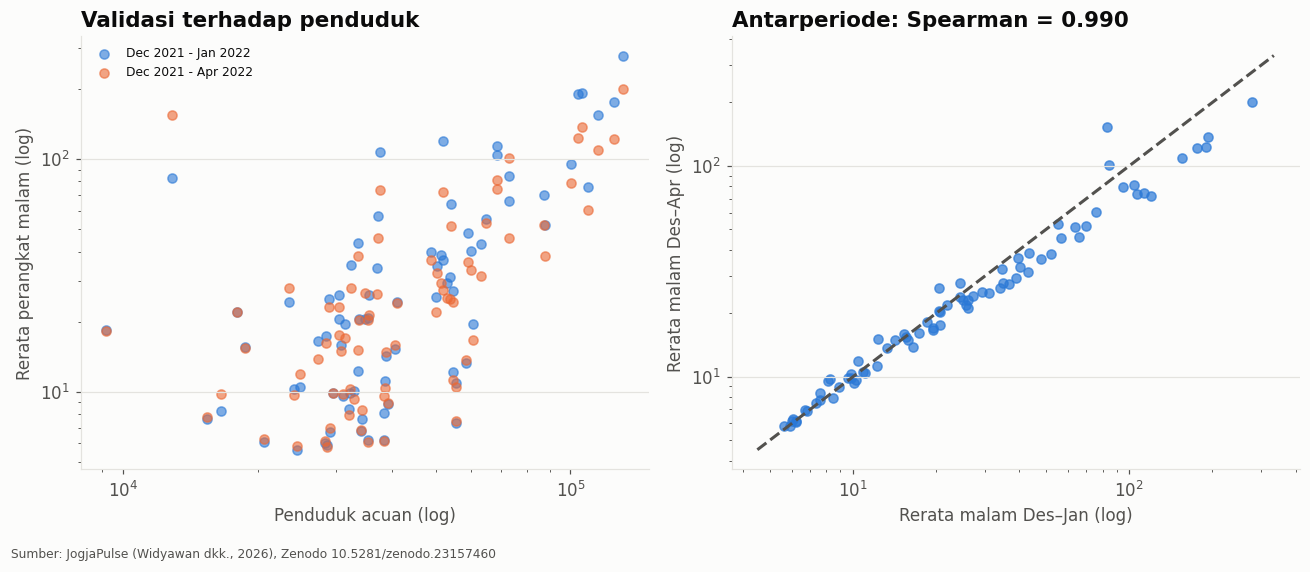

In [4]:
records=[]
for period, sub in night.groupby('period'):
    for scope in ['Semua wilayah','Tanpa Gondomanan']:
        selected=sub if scope=='Semua wilayah' else sub[~((sub.kab_kota=='YOGYAKARTA') & (sub.kapanewon=='GONDOMANAN'))]
        for ref in ['pop_actual','n_users']:
            records.append({'period':period,'cakupan':scope,'pembanding':ref,**correlations(selected,ref,'night_presence')})
night_corr=pd.DataFrame(records)
display(night_corr.round(3))
paired=night.pivot(index=KEY,columns='period',values='night_presence').reset_index()
period_corr=correlations(paired,SHORT,FULL)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for period in PERIODS:
    sub=night[night.period==period]
    axes[0].scatter(sub.pop_actual,sub.night_presence,label=period,alpha=.6)
axes[0].set(xscale='log',yscale='log',xlabel='Penduduk acuan (log)',ylabel='Rerata perangkat malam (log)',title='Validasi terhadap penduduk')
axes[0].legend(fontsize=8)
axes[1].scatter(paired[SHORT],paired[FULL],alpha=.7,color=style.CATEGORICAL[0])
lo=min(paired[SHORT].min(),paired[FULL].min())*.8
hi=max(paired[SHORT].max(),paired[FULL].max())*1.2
axes[1].plot([lo,hi],[lo,hi],'--',color=style.TEXT_SECONDARY)
axes[1].set(xscale='log',yscale='log',xlabel='Rerata malam Des–Jan (log)',ylabel='Rerata malam Des–Apr (log)',title=f"Antarperiode: Spearman = {period_corr['Spearman']:.3f}")
fig.tight_layout()
save_plot(fig,'E_03_validasi_malam')


## 5. Audit ulang validasi dan kelengkapan slot malam
Rekonstruksi ini memakai data per jam sebagai pemeriksaan perhitungan, bukan sumber independen. Cakupan dihitung dari jumlah slot terbit dibagi jumlah hari × 6. Cakupan rendah dapat membuat rerata terbit condong ke jam yang lebih ramai; nilainya tidak boleh dianggap rerata seluruh jam.


Lulus: 156 rerata malam dan cakupan slot cocok dengan rekonstruksi CSV per jam.


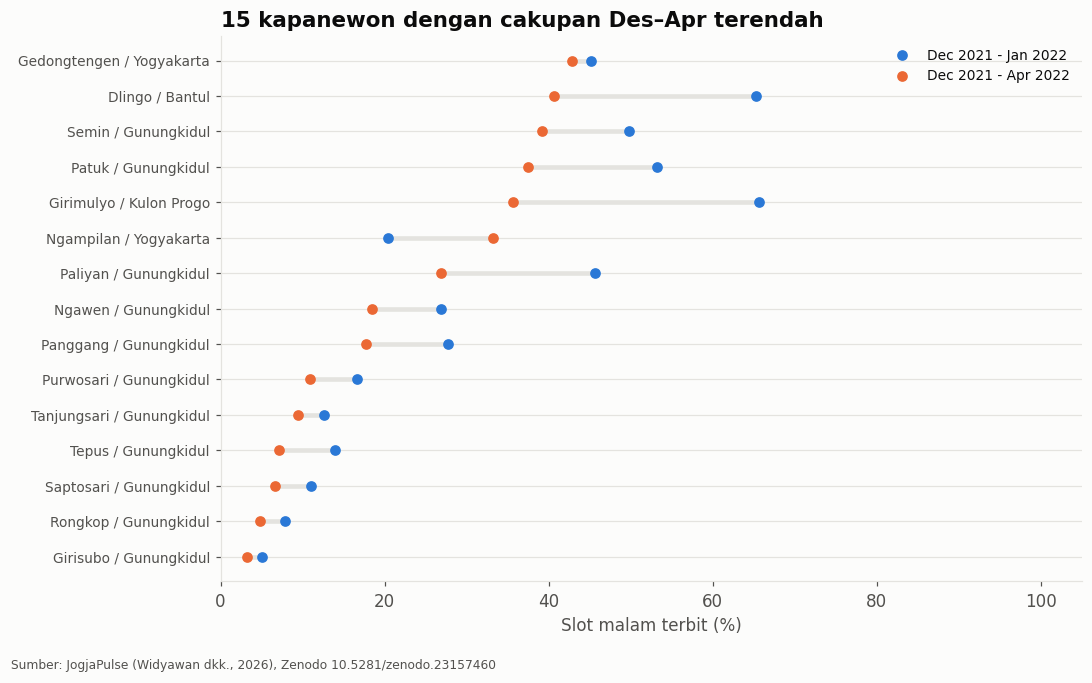

,min,median,max
period,,,
Dec 2021 - Apr 2022,3.20,69.32,100.0
Dec 2021 - Jan 2022,5.11,98.92,100.0


In [5]:
hourly=io.load_presence_hourly()
assert not hourly.duplicated(KEY+['date','hour']).any()
assert hourly.n_maids.ge(5).all()
reconstructed=[]
for period,(start,end) in PERIODS.items():
    sub=hourly[hourly.date.between(start,end) & hourly.hour.between(0,5)]
    calc=sub.groupby(KEY).agg(night_presence=('n_maids','mean'),slots=('n_maids','size')).reset_index()
    days=(pd.Timestamp(end)-pd.Timestamp(start)).days+1
    calc['slots_published_pct']=100*calc.slots/(days*6)
    calc['period']=period
    reconstructed.append(calc)
audit=night.merge(pd.concat(reconstructed),on=['period']+KEY,validate='one_to_one',how='outer',indicator=True,suffixes=('_source','_calc'))
assert audit['_merge'].eq('both').all()
for col in ['night_presence','slots_published_pct']:
    np.testing.assert_allclose(audit[col+'_source'],audit[col+'_calc'],rtol=1e-7,atol=1e-7)
print('Lulus: 156 rerata malam dan cakupan slot cocok dengan rekonstruksi CSV per jam.')
coverage=night.pivot(index=KEY,columns='period',values='slots_published_pct')
coverage=coverage.sort_values(FULL)
fig,ax=plt.subplots(figsize=(10,6))
y=np.arange(15)
low=coverage.head(15)
ax.hlines(y,low[SHORT],low[FULL],color=style.GRID,linewidth=3)
for period,color in zip(PERIODS,style.CATEGORICAL):
    ax.scatter(low[period],y,label=period,color=color,zorder=3)
ax.set_yticks(y, [f'{k.title()} / {b.title()}' for b,k in low.index],fontsize=9)
ax.set(xlim=(0,105),xlabel='Slot malam terbit (%)',title='15 kapanewon dengan cakupan Des–Apr terendah')
ax.legend(fontsize=9)
fig.tight_layout()
save_plot(fig,'E_04_cakupan_slot_malam')
display(night.groupby('period').slots_published_pct.agg(['min','median','max']).round(2))


## 6. Supresi: banyak baris hilang, bobotnya tidak sama
Persentase baris tersupresi berbeda dari persentase bobot hitungan yang hilang. Bobot presence adalah penjumlahan *device-presence*; bobot OD adalah hitungan pengunjung per pasangan antarwilayah. Keduanya bukan jumlah orang unik, dan bobot OD hanya pasangan asal ≠ tujuan.

`rows_total` adalah baris sebelum supresi menurut pembuat dataset, bukan semua kemungkinan sel × hari atau kapanewon × jam. Karena itu, persentase supresi resmi tidak sama dengan persentase slot malam yang hilang pada grafik sebelumnya.


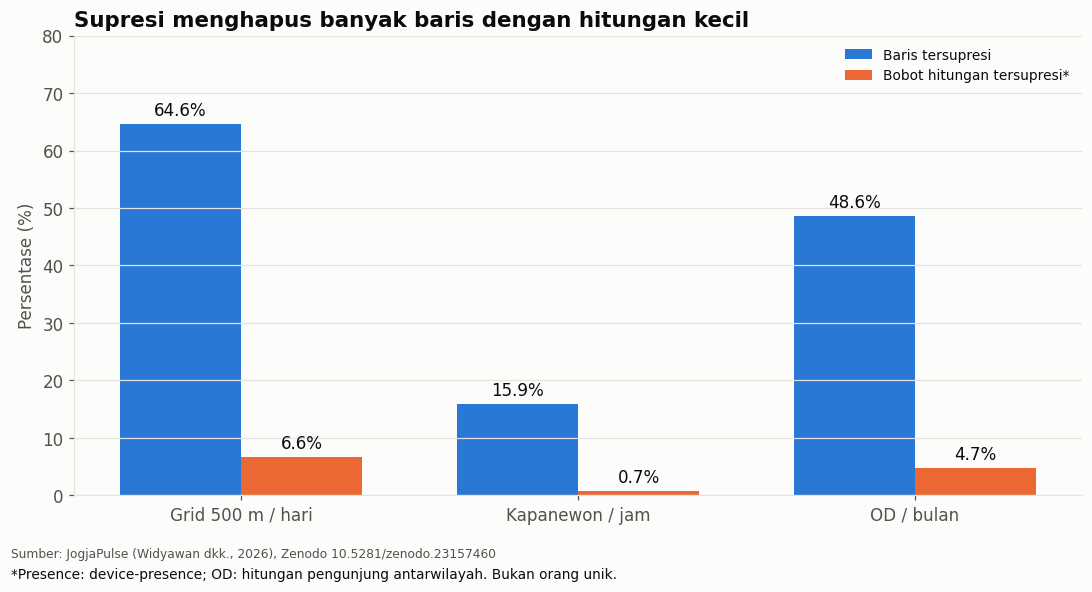

,produk,baris_tersupresi_pct,bobot_tersupresi_pct
0,Grid 500 m / hari,64.6,6.6
1,Kapanewon / jam,15.9,0.7
2,OD / bulan,48.6,4.7


In [6]:
assert tier.k.eq(5).all() and od.k.eq(5).all()
np.testing.assert_allclose(100*(1-tier.rows_published/tier.rows_total),tier.rows_suppressed_pct,atol=.051)
np.testing.assert_allclose(100*(1-od.od_rows_published/od.od_rows_total),od.od_rows_suppressed_pct,atol=.051)
tier=tier.set_index('product').loc[['A_cell500m_daily','B_kapanewon_hourly']].reset_index()
suppression=pd.DataFrame({
    'produk':['Grid 500 m / hari','Kapanewon / jam','OD / bulan'],
    'baris_tersupresi_pct':[*tier.rows_suppressed_pct,od.od_rows_suppressed_pct.iloc[0]],
    'bobot_tersupresi_pct':[*tier.maid_presence_suppressed_pct,100-od.inter_zonal_flow_kept_pct.iloc[0]]})
fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(3)
for offset,col,label,color in [(-.18,'baris_tersupresi_pct','Baris tersupresi',style.CATEGORICAL[0]),(.18,'bobot_tersupresi_pct','Bobot hitungan tersupresi*',style.CATEGORICAL[1])]:
    bars=ax.bar(x+offset,suppression[col],.36,label=label,color=color)
    ax.bar_label(bars,fmt='%.1f%%',padding=3)
ax.set_xticks(x,suppression.produk)
ax.set(ylim=(0,80),ylabel='Persentase (%)',title='Supresi menghapus banyak baris dengan hitungan kecil')
ax.legend(fontsize=9)
fig.text(.01,-.065,'*Presence: device-presence; OD: hitungan pengunjung antarwilayah. Bukan orang unik.',fontsize=9)
fig.tight_layout()
save_plot(fig,'E_05_supresi')
display(suppression.round(1))


## 7. Temuan untuk presentasi dan batas interpretasi
Angka berikut dibuat langsung dari hasil analisis agar tetap sesuai ketika notebook dijalankan ulang.


In [7]:
g=home.loc[~without_g].iloc[0]
lowrow=home.loc[home.ratio.idxmin()]
full_night=night[night.period==FULL]
text=f"""### Ringkasan hasil E
- Pada 78 kapanewon, korelasi perangkat rumah dengan penduduk: Pearson **{home_corr.iloc[0]['Pearson']:.3f}**, Pearson log10 **{home_corr.iloc[0]['Pearson_log10']:.3f}**, Spearman **{home_corr.iloc[0]['Spearman']:.3f}**. Hubungan spasial tidak membuktikan keterwakilan individu.
- Rasio berkisar **{lowrow.perangkat_per_100_penduduk:.2f}** perangkat per 100 penduduk ({lowrow.kapanewon.title()}, {lowrow.kab_kota.title()}) sampai **{g.perangkat_per_100_penduduk:.2f}** di Gondomanan. Ini bukan persentase penduduk yang memakai aplikasi.
- Peringkat rerata malam antarperiode berkorelasi **{period_corr['Spearman']:.3f}**. Dua periode bertumpang tindih dan level hitungan dipengaruhi perubahan sampel.
- Cakupan malam Des–Apr terendah **{full_night.slots_published_pct.min():.2f}%**, median **{full_night.slots_published_pct.median():.2f}%**. Rerata wilayah dengan cakupan rendah harus dibaca bersama kelengkapan slotnya.
- Supresi menghapus **{suppression.iloc[0].baris_tersupresi_pct:.1f}%** baris grid harian, **{suppression.iloc[1].baris_tersupresi_pct:.1f}%** baris kapanewon per jam, dan **{suppression.iloc[2].baris_tersupresi_pct:.1f}%** baris OD. Baris hilang bukan nol.

### Batas kesimpulan dan implikasi untuk A–D
1. Sampel berasal dari aplikasi dengan izin lokasi; perangkat bukan orang dan sampelnya bukan acak. Dugaan kunjungan/wisata sebagai sebab rasio Gondomanan tinggi berasal dari README sumber, belum diuji di sini.
2. A dan B: bandingkan profil yang dinormalisasi pada Des–Feb, serta periksa supresi dan gangguan per jam sesuai README proyek.
3. C: analisis kejadian seluruh periode memerlukan normalisasi harian dan penandaan perubahan sampel; perubahan angka mentah tidak membuktikan dampak kejadian.
4. D: batasi analisis kuantitatif ke Des–Feb; OD mengukur pengunjung, bukan perjalanan. Rumah bulanan OD berbeda definisi dengan estimasi rumah seluruh periode pada file validasi ini.
5. Tandai 1 Januari, 16 Februari, dan 8 Maret 2022 sesuai README. Validasi ini tidak mengisolasi efek anomali tersebut atau membuktikan sebab penurunan sampel.
6. Sumber/tahun penduduk BPS dan rincian estimasi rumah seluruh periode belum lengkap pada README dataset; konfirmasi sebelum laporan final. File agregat tidak cukup untuk menguji bias usia, gender, atau pengguna aplikasi.

### Kaitan dengan hasil B: pola klaster dan kualitas data
Sumber pembahasan ini adalah [notebook B](B_klaster_kapanewon.ipynb), versi yang masuk ke `main` pada commit `5ddca5f`. Angka B di bawah merupakan hasil yang dilaporkan notebook tersebut, bukan hasil perhitungan ulang oleh E.

- B membagi 78 kapanewon menjadi puncak siang (36), puncak petang (39), dan tiga profil tak lazim: Girisubo, Rongkop, serta Gondomanan. Silhouette k = 3 sebesar 0,230 menunjukkan kelompok masih tumpang tindih; label klaster merangkum profil perangkat, belum membuktikan fungsi hunian, pusat kegiatan, atau wisata.
- Girisubo dan Rongkop masing-masing memiliki sekitar 66% dan 54% slot yang diisi pada analisis B. Gondomanan memiliki lonjakan indeks pukul 01.00-02.00 yang, menurut pembahasan A/B, membesar setelah perubahan sampel. Karena itu, ketiganya perlu dibaca bersama indikator kualitas sebelum pola tersebut ditafsirkan sebagai perilaku mobilitas.
- **Penyebut dan periode berbeda:** indikator B adalah proporsi slot yang diisi pada profil hari kerja Desember-Februari dari A; indikator E adalah proporsi slot malam 00.00-05.59 yang terbit pada Desember-Januari atau Desember-April. Angka keduanya tidak dapat langsung dibandingkan atau dianggap saling melengkapi menjadi 100%.
- Dalam uji B, setelah sembilan wilayah bercakupan rendah dan Gondomanan dikeluarkan, pembagian dua klaster utama tetap sama pada 68 dari 68 wilayah (ARI 1,00). Saat hanya tiga profil tak lazim dikeluarkan, 73 dari 75 penempatan tetap sama (ARI 0,895). Ini mendukung kestabilan pembagian utama terhadap pemilihan wilayah, tetapi belum menguji sensitivitas terhadap nilai isian slot yang hilang.
- Temuan B selaras dengan perhatian E pada supresi dan ketidakseragaman rasio perangkat. Namun, E tidak membuktikan bahwa supresi menyebabkan keanggotaan klaster tertentu, dan rasio perangkat Gondomanan yang tinggi tidak menjelaskan sendiri lonjakan profil malamnya.

### Narasi singkat video
Data ini memperlihatkan hubungan antara distribusi perangkat dan jumlah penduduk, tetapi cakupannya berbeda antarwilayah. Jumlah perangkat tidak sama dengan jumlah orang. Sebagian slot juga tidak diterbitkan karena hitungannya kecil, sehingga data kosong tidak boleh dibaca sebagai nol. Karena sampel berubah sepanjang waktu, hasil kelompok perlu memakai normalisasi, periode yang sesuai, dan penjelasan keterbatasan.
"""
display(Markdown(text))
home.to_csv(io.PROCESSED_DIR/'E_rasio_perangkat.csv',index=False)
home_corr.to_csv(io.PROCESSED_DIR/'E_korelasi_rumah.csv')
night_corr.to_csv(io.PROCESSED_DIR/'E_korelasi_malam.csv',index=False)
coverage.to_csv(io.PROCESSED_DIR/'E_cakupan_malam.csv')
suppression.to_csv(io.PROCESSED_DIR/'E_supresi.csv',index=False)
(io.PROCESSED_DIR/'E_ringkasan.md').write_text(text,encoding='utf-8')
print('Tersimpan: 5 grafik di figures/ dan tabel/ringkasan di data/processed/.')


### Ringkasan hasil E
- Pada 78 kapanewon, korelasi perangkat rumah dengan penduduk: Pearson **0.723**, Pearson log10 **0.600**, Spearman **0.614**. Hubungan spasial tidak membuktikan keterwakilan individu.
- Rasio berkisar **0.94** perangkat per 100 penduduk (Tepus, Gunungkidul) sampai **224.70** di Gondomanan. Ini bukan persentase penduduk yang memakai aplikasi.
- Peringkat rerata malam antarperiode berkorelasi **0.990**. Dua periode bertumpang tindih dan level hitungan dipengaruhi perubahan sampel.
- Cakupan malam Des–Apr terendah **3.20%**, median **69.32%**. Rerata wilayah dengan cakupan rendah harus dibaca bersama kelengkapan slotnya.
- Supresi menghapus **64.6%** baris grid harian, **15.9%** baris kapanewon per jam, dan **48.6%** baris OD. Baris hilang bukan nol.

### Batas kesimpulan dan implikasi untuk A–D
1. Sampel berasal dari aplikasi dengan izin lokasi; perangkat bukan orang dan sampelnya bukan acak. Dugaan kunjungan/wisata sebagai sebab rasio Gondomanan tinggi berasal dari README sumber, belum diuji di sini.
2. A dan B: bandingkan profil yang dinormalisasi pada Des–Feb, serta periksa supresi dan gangguan per jam sesuai README proyek.
3. C: analisis kejadian seluruh periode memerlukan normalisasi harian dan penandaan perubahan sampel; perubahan angka mentah tidak membuktikan dampak kejadian.
4. D: batasi analisis kuantitatif ke Des–Feb; OD mengukur pengunjung, bukan perjalanan. Rumah bulanan OD berbeda definisi dengan estimasi rumah seluruh periode pada file validasi ini.
5. Tandai 1 Januari, 16 Februari, dan 8 Maret 2022 sesuai README. Validasi ini tidak mengisolasi efek anomali tersebut atau membuktikan sebab penurunan sampel.
6. Sumber/tahun penduduk BPS dan rincian estimasi rumah seluruh periode belum lengkap pada README dataset; konfirmasi sebelum laporan final. File agregat tidak cukup untuk menguji bias usia, gender, atau pengguna aplikasi.

### Kaitan dengan hasil B: pola klaster dan kualitas data
Sumber pembahasan ini adalah [notebook B](B_klaster_kapanewon.ipynb), versi yang masuk ke `main` pada commit `5ddca5f`. Angka B di bawah merupakan hasil yang dilaporkan notebook tersebut, bukan hasil perhitungan ulang oleh E.

- B membagi 78 kapanewon menjadi puncak siang (36), puncak petang (39), dan tiga profil tak lazim: Girisubo, Rongkop, serta Gondomanan. Silhouette k = 3 sebesar 0,230 menunjukkan kelompok masih tumpang tindih; label klaster merangkum profil perangkat, belum membuktikan fungsi hunian, pusat kegiatan, atau wisata.
- Girisubo dan Rongkop masing-masing memiliki sekitar 66% dan 54% slot yang diisi pada analisis B. Gondomanan memiliki lonjakan indeks pukul 01.00-02.00 yang, menurut pembahasan A/B, membesar setelah perubahan sampel. Karena itu, ketiganya perlu dibaca bersama indikator kualitas sebelum pola tersebut ditafsirkan sebagai perilaku mobilitas.
- **Penyebut dan periode berbeda:** indikator B adalah proporsi slot yang diisi pada profil hari kerja Desember-Februari dari A; indikator E adalah proporsi slot malam 00.00-05.59 yang terbit pada Desember-Januari atau Desember-April. Angka keduanya tidak dapat langsung dibandingkan atau dianggap saling melengkapi menjadi 100%.
- Dalam uji B, setelah sembilan wilayah bercakupan rendah dan Gondomanan dikeluarkan, pembagian dua klaster utama tetap sama pada 68 dari 68 wilayah (ARI 1,00). Saat hanya tiga profil tak lazim dikeluarkan, 73 dari 75 penempatan tetap sama (ARI 0,895). Ini mendukung kestabilan pembagian utama terhadap pemilihan wilayah, tetapi belum menguji sensitivitas terhadap nilai isian slot yang hilang.
- Temuan B selaras dengan perhatian E pada supresi dan ketidakseragaman rasio perangkat. Namun, E tidak membuktikan bahwa supresi menyebabkan keanggotaan klaster tertentu, dan rasio perangkat Gondomanan yang tinggi tidak menjelaskan sendiri lonjakan profil malamnya.

### Narasi singkat video
Data ini memperlihatkan hubungan antara distribusi perangkat dan jumlah penduduk, tetapi cakupannya berbeda antarwilayah. Jumlah perangkat tidak sama dengan jumlah orang. Sebagian slot juga tidak diterbitkan karena hitungannya kecil, sehingga data kosong tidak boleh dibaca sebagai nol. Karena sampel berubah sepanjang waktu, hasil kelompok perlu memakai normalisasi, periode yang sesuai, dan penjelasan keterbatasan.


Tersimpan: 5 grafik di figures/ dan tabel/ringkasan di data/processed/.
